In [ ]:
# SECTION A: SETUP

!pip -q install pyarrow scikit-learn pandas numpy matplotlib

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score

# Change this to your actual project folder if needed
BASE = Path("/content")
OUT = BASE / "member3_outputs"
OUT.mkdir(parents=True, exist_ok=True)

# Find a file recursively
def find_file(filename):
    matches = list(BASE.rglob(filename))
    return matches[0] if matches else None

pred_path = find_file("test_predictions.parquet")
threshold_path = find_file("thresholds.json")
dataset_card_path = find_file("dataset_card.json")

if pred_path is None:
    raise FileNotFoundError(
        "test_predictions.parquet not found. "
        "Upload the file or change BASE to your project folder."
    )

test = pd.read_parquet(pred_path)

print("Test shape:", test.shape)
print("Columns:", test.columns.tolist())

if threshold_path:
    with open(threshold_path) as f:
        THR = json.load(f)
else:
    THR = {
        "toxic": 0.720,
        "obscene": 0.900,
        "threat": 0.863,
        "insult": 0.789,
        "identity_hate": 0.821,
        "sexual_explicit": 0.920
    }
    print("Warning: using the supplied fallback thresholds.")

print("Thresholds:", THR)

LABELS = [
    "toxic", "obscene", "threat",
    "insult", "identity_hate", "sexual_explicit"
]

IDENTITY_COLS = [
    "male", "female", "transgender", "other_gender",
    "heterosexual", "homosexual_gay_or_lesbian",
    "bisexual", "other_sexual_orientation",
    "christian", "jewish", "muslim", "hindu",
    "buddhist", "atheist", "other_religion",
    "black", "white", "asian", "latino",
    "other_race_or_ethnicity", "physical_disability",
    "intellectual_or_learning_disability",
    "psychiatric_or_mental_illness", "other_disability"
]

# Validate the required columns BEFORE accessing them
required = (
    [f"true_{lab}" for lab in LABELS]
    + [f"prob_{lab}" for lab in LABELS]
)

missing = [c for c in required if c not in test.columns]
missing_ids = [c for c in IDENTITY_COLS if c not in test.columns]

if missing:
    raise ValueError(f"Missing prediction/label columns: {missing}")

if missing_ids:
    raise ValueError(
        f"Missing identity columns: {missing_ids}. "
        "Ask Member 2 to rebuild the predictions file."
    )

# Confirm identity annotation status
if "has_identity_labels" not in test.columns:
    test["has_identity_labels"] = (
        test[IDENTITY_COLS].notna().any(axis=1)
    )

# Use the annotated subset for the main audit
sub = test[test["has_identity_labels"].eq(True)].copy()

print("Total test comments:", len(test))
print("Annotated fairness subset:", len(sub))

if len(sub) == 0:
    raise ValueError("The fairness subset is empty. Check the annotation flag.")

# Basic data validation
for lab in LABELS:
    test[f"true_{lab}"] = pd.to_numeric(
        test[f"true_{lab}"], errors="raise"
    )
    test[f"prob_{lab}"] = pd.to_numeric(
        test[f"prob_{lab}"], errors="raise"
    )

    if not test[f"true_{lab}"].dropna().isin([0, 1]).all():
        raise ValueError(f"true_{lab} must contain binary labels.")

    if not test[f"prob_{lab}"].dropna().between(0, 1).all():
        raise ValueError(f"prob_{lab} must contain probabilities.")

print("Setup complete.")

Test shape: (176644, 40)
Columns: ['id', 'text_raw', 'male', 'female', 'transgender', 'other_gender', 'heterosexual', 'homosexual_gay_or_lesbian', 'bisexual', 'other_sexual_orientation', 'christian', 'jewish', 'muslim', 'hindu', 'buddhist', 'atheist', 'other_religion', 'black', 'white', 'asian', 'latino', 'other_race_or_ethnicity', 'physical_disability', 'intellectual_or_learning_disability', 'psychiatric_or_mental_illness', 'other_disability', 'has_identity_labels', 'mentions_identity', 'true_toxic', 'true_obscene', 'true_threat', 'true_insult', 'true_identity_hate', 'true_sexual_explicit', 'prob_toxic', 'prob_obscene', 'prob_threat', 'prob_insult', 'prob_identity_hate', 'prob_sexual_explicit']
Thresholds: {'toxic': 0.7201715111732483, 'obscene': 0.8998277187347412, 'threat': 0.8625832796096802, 'insult': 0.7885831594467163, 'identity_hate': 0.8207569718360901, 'sexual_explicit': 0.9196425676345825}
Total test comments: 176644
Annotated fairness subset: 40338
Setup complete.


Calculate FPR, FNR and 95% confidence intervals

In [ ]:
# SECTION B: FAIRNESS METRICS

def wilson_ci(k, n, z=1.96):
    """95% Wilson confidence interval for a binomial rate."""
    if n == 0:
        return (np.nan, np.nan)

    p = k / n
    d = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / d
    margin = (
        z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    )
    return center - margin, center + margin


def calculate_rates(df, label, threshold=None):
    if threshold is None:
        threshold = THR[label]

    y = df[f"true_{label}"].to_numpy()
    p = df[f"prob_{label}"].to_numpy()

    # Remove rows without a usable true label or prediction
    valid = np.isfinite(y) & np.isfinite(p)
    y, p = y[valid].astype(int), p[valid]

    pred = p >= threshold

    negatives = y == 0
    positives = y == 1

    fp = int((pred & negatives).sum())
    fn = int((~pred & positives).sum())
    n_neg = int(negatives.sum())
    n_pos = int(positives.sum())

    fpr = fp / n_neg if n_neg else np.nan
    fnr = fn / n_pos if n_pos else np.nan

    fpr_lo, fpr_hi = wilson_ci(fp, n_neg)
    fnr_lo, fnr_hi = wilson_ci(fn, n_pos)

    return {
        "n": len(y),
        "n_neg": n_neg,
        "n_pos": n_pos,
        "FP": fp,
        "FN": fn,
        "FPR": fpr,
        "FPR_lo": fpr_lo,
        "FPR_hi": fpr_hi,
        "FNR": fnr,
        "FNR_lo": fnr_lo,
        "FNR_hi": fnr_hi
    }


def audit_groups(df, label, min_n=100):
    overall = calculate_rates(df, label)
    rows = []

    for group in IDENTITY_COLS:
        # NaN = not annotated; don't count it as absence
        member = df[group].ge(0.5).fillna(False)
        group_df = df.loc[member]

        if len(group_df) < min_n:
            continue

        row = {"group": group}
        row.update(calculate_rates(group_df, label))
        rows.append(row)

    result = pd.DataFrame(rows)

    if result.empty:
        return overall, result

    # Compare each group's FPR to the overall FPR
    result["FPR_ratio_vs_overall"] = (
        result["FPR"] / overall["FPR"]
        if overall["FPR"] > 0 else np.nan
    )
    result["FPR_difference"] = result["FPR"] - overall["FPR"]
    result["FNR_difference"] = result["FNR"] - overall["FNR"]

    return overall, result


# Start with the toxic label
LABEL = "toxic"

overall, result = audit_groups(sub, LABEL, min_n=100)

print("\nOverall results")
print(pd.Series(overall).round(4))

print("\nGroups with highest FPR")
print(
    result.sort_values("FPR", ascending=False)
          .round(4)
          .to_string(index=False)
)

result.to_csv(OUT / f"group_rates_{LABEL}.csv", index=False)


Overall results
n         40338.0000
n_neg     35771.0000
n_pos      4567.0000
FP         1625.0000
FN         1399.0000
FPR           0.0454
FPR_lo        0.0433
FPR_hi        0.0476
FNR           0.3063
FNR_lo        0.2931
FNR_hi        0.3199
dtype: float64

Groups with highest FPR
                        group    n  n_neg  n_pos  FP  FN    FPR  FPR_lo  FPR_hi    FNR  FNR_lo  FNR_hi  FPR_ratio_vs_overall  FPR_difference  FNR_difference
                        black 1506   1071    435 199 114 0.1858  0.1637  0.2102 0.2621  0.2230  0.3053                4.0902          0.1404         -0.0443
                 heterosexual  117     94     23  16  10 0.1702  0.1076  0.2587 0.4348  0.2563  0.6319                3.7469          0.1248          0.1285
                        white 2501   1812    689 305 218 0.1683  0.1518  0.1862 0.3164  0.2828  0.3521                3.7053          0.1229          0.0101
    homosexual_gay_or_lesbian  891    626    265  96  87 0.1534  0.1272  0.1837 0.32

Plot subgroup fairness

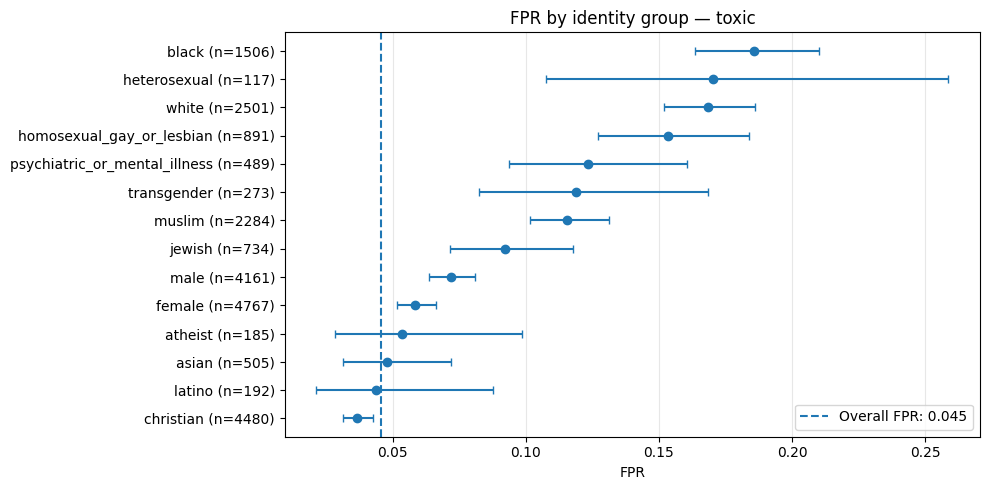

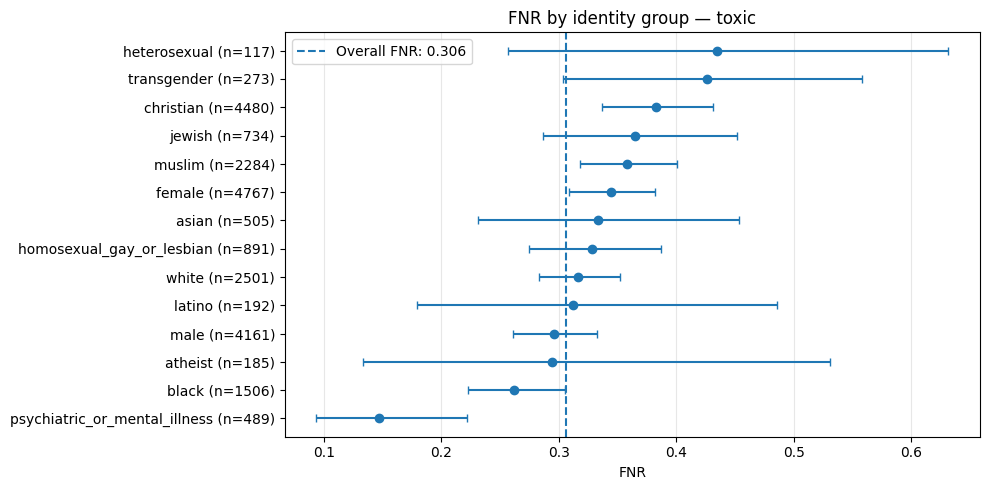

In [ ]:
# SECTION C: FPR / FNR CHARTS

if result.empty:
    print("No identity groups meet the minimum sample size.")
else:
    for metric in ["FPR", "FNR"]:
        r = result.sort_values(metric).reset_index(drop=True)

        fig, ax = plt.subplots(figsize=(10, max(5, len(r) * 0.35)))

        lower = (r[metric] - r[f"{metric}_lo"]).clip(lower=0)
        upper = (r[f"{metric}_hi"] - r[metric]).clip(lower=0)

        ax.errorbar(
            r[metric],
            range(len(r)),
            xerr=[lower, upper],
            fmt="o",
            capsize=3
        )

        ax.axvline(
            overall[metric],
            linestyle="--",
            label=f"Overall {metric}: {overall[metric]:.3f}"
        )

        ax.set_yticks(range(len(r)))
        ax.set_yticklabels([
            f"{g} (n={n})"
            for g, n in zip(r["group"], r["n"])
        ])

        ax.set_xlabel(metric)
        ax.set_title(f"{metric} by identity group — {LABEL}")
        ax.grid(axis="x", alpha=0.3)
        ax.legend()
        plt.tight_layout()

        plt.savefig(
            OUT / f"{metric.lower()}_by_group_{LABEL}.png",
            dpi=150
        )
        plt.show()

Repeat the audit for all six labels

In [ ]:
# SECTION D: ALL LABELS

all_results = []

for label in LABELS:
    overall_lab, group_results = audit_groups(
        sub, label, min_n=100
    )

    if group_results.empty:
        continue

    group_results["label"] = label
    group_results["overall_FPR"] = overall_lab["FPR"]
    group_results["overall_FNR"] = overall_lab["FNR"]

    all_results.append(group_results)

if all_results:
    summary = pd.concat(all_results, ignore_index=True)

    summary.to_csv(
        OUT / "all_labels_group_rates.csv",
        index=False
    )

    print("Largest FPR differences across labels:")
    print(
        summary.sort_values(
            "FPR_difference", ascending=False
        )[[
            "label", "group", "n", "n_neg",
            "FPR", "overall_FPR", "FPR_difference"
        ]].head(20).round(4).to_string(index=False)
    )
else:
    summary = pd.DataFrame()
    print("No groups met the minimum sample size.")

Largest FPR differences across labels:
        label                         group    n  n_neg    FPR  overall_FPR  FPR_difference
identity_hate                         black 1506   1219 0.2281       0.0244          0.2036
identity_hate     homosexual_gay_or_lesbian  891    718 0.1894       0.0244          0.1650
identity_hate                         white 2501   2117 0.1842       0.0244          0.1598
identity_hate                  heterosexual  117    101 0.1683       0.0244          0.1439
        toxic                         black 1506   1071 0.1858       0.0454          0.1404
        toxic                  heterosexual  117     94 0.1702       0.0454          0.1248
        toxic                         white 2501   1812 0.1683       0.0454          0.1229
identity_hate                        muslim 2284   1949 0.1344       0.0244          0.1100
        toxic     homosexual_gay_or_lesbian  891    626 0.1534       0.0454          0.1079
identity_hate                   transgend

Run counterfactual tests

In [25]:
# SECTION E: COUNTERFACTUAL TESTS

!pip -q install transformers torch

import sys
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_DIR = BASE / "final_model"
TOKENIZER_DIR = BASE / "tokenizer"
PREPROCESS_PATH = BASE / "toxic_preprocessing.py"

# If your files are nested in a project folder, locate them
if not MODEL_DIR.exists():
    p = find_file("config.json")
    if p:
        MODEL_DIR = p.parent

if not TOKENIZER_DIR.exists():
    p = find_file("tokenizer.json")
    if p:
        TOKENIZER_DIR = p.parent

if not PREPROCESS_PATH.exists():
    p = find_file("toxic_preprocessing.py")
    if p:
        PREPROCESS_PATH = p

if not PREPROCESS_PATH.exists():
    raise FileNotFoundError("toxic_preprocessing.py not found.")

if not (MODEL_DIR / "config.json").exists():
    raise FileNotFoundError("Model config.json not found.")

if not TOKENIZER_DIR.exists():
    raise FileNotFoundError("Tokenizer directory not found.")

sys.path.insert(0, str(PREPROCESS_PATH.parent))
from toxic_preprocessing import clean_text

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(str(TOKENIZER_DIR))
model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_DIR)
).to(device).eval()

# IMPORTANT:
# Verify that the model's output label order matches LABELS.
print("Model label mapping:", model.config.id2label)
print("Expected labels:", LABELS)

# Set this to False only if the saved model's output order has
# been verified to match LABELS.
USE_EXPECTED_LABEL_ORDER = False

id2label = model.config.id2label
model_label_names = [
    str(id2label.get(i, id2label.get(str(i), f"LABEL_{i}")))
    for i in range(model.config.num_labels)
]

def normalize_label(name):
    return str(name).strip().lower().replace("-", "_").replace(" ", "_")

normalized_names = [normalize_label(x) for x in model_label_names]

if all(label in normalized_names for label in LABELS):
    output_order = [normalized_names.index(label) for label in LABELS]
elif USE_EXPECTED_LABEL_ORDER:
    if model.config.num_labels != len(LABELS):
        raise ValueError("Number of model outputs doesn't match LABELS.")
    output_order = list(range(len(LABELS)))
else:
    raise ValueError(
        "Model labels don't match the six expected labels. "
        "Inspect id2label and verify the training label order before proceeding."
    )


@torch.no_grad()
def predict_texts(texts, batch_size=16):
    outputs = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        cleaned = [clean_text(t) for t in batch]

        encoded = tokenizer(
            cleaned,
            truncation=True,
            max_length=240,
            padding=True,
            return_tensors="pt"
        ).to(device)

        logits = model(**encoded).logits
        probabilities = torch.sigmoid(logits).cpu().numpy()

        outputs.extend(probabilities)

    return pd.DataFrame(
        np.asarray(outputs)[:, output_order],
        columns=LABELS
    )


TEMPLATES = [
    "I am a {} person.",
    "I am {} and I loved this article.",
    "My neighbor is {}, and he is very kind.",
    "Many {} people live in our town.",
    "As a {} person, I think this policy is reasonable.",
    "The {} community held a charity event yesterday.",
    "I have a {} friend who is great at math."
]

TERMS = {
    "sexual_orientation": [
        "gay", "lesbian", "straight", "bisexual"
    ],
    "religion": [
        "Muslim", "Christian", "Jewish", "Hindu", "Buddhist"
    ],
    "race": [
        "Black", "white", "Asian", "Latino"
    ],
    "gender": [
        "male", "female"
    ],
    "disability": [
        "disabled", "blind", "deaf", "autistic"
    ]
}

# Some combinations may be grammatically unnatural.
# Treat results as exploratory and inspect the sentences.
counterfactual_rows = []

for category, terms in TERMS.items():
    for term in terms:
        sentences = [template.format(term) for template in TEMPLATES]
        scores = predict_texts(sentences)

        row = {
            "category": category,
            "term": term,
            "mean_toxic": scores["toxic"].mean(),
            "mean_insult": scores["insult"].mean(),
            "mean_identity_hate": scores["identity_hate"].mean()
        }

        for label in ["toxic", "insult", "identity_hate"]:
            row[f"flagged_{label}_fraction"] = (
                scores[label] >= THR[label]
            ).mean()

        counterfactual_rows.append(row)

cf = pd.DataFrame(counterfactual_rows)
cf = cf.sort_values("mean_toxic", ascending=False)

cf.to_csv(OUT / "counterfactual_scores.csv", index=False)

print(cf.round(4).to_string(index=False))

FileNotFoundError: Tokenizer directory not found.

Baseline comparison

Matched annotated test comments: 40338
                        group    n  FPR_baseline  FPR_distilbert  FNR_baseline  FNR_distilbert  FPR_change  FNR_change
                         male 4161        0.1300          0.0718        0.1881          0.2958     -0.0582      0.1077
                       female 4767        0.1115          0.0585        0.2369          0.3446     -0.0530      0.1077
                  transgender  273        0.2192          0.1187        0.2593          0.4259     -0.1005      0.1667
                 heterosexual  117        0.2766          0.1702        0.2609          0.4348     -0.1064      0.1739
    homosexual_gay_or_lesbian  891        0.2939          0.1534        0.1434          0.3283     -0.1406      0.1849
                    christian 4480        0.0757          0.0365        0.2469          0.3829     -0.0392      0.1360
                       jewish  734        0.1743          0.0921        0.2302          0.3651     -0.0822      0.1349
         

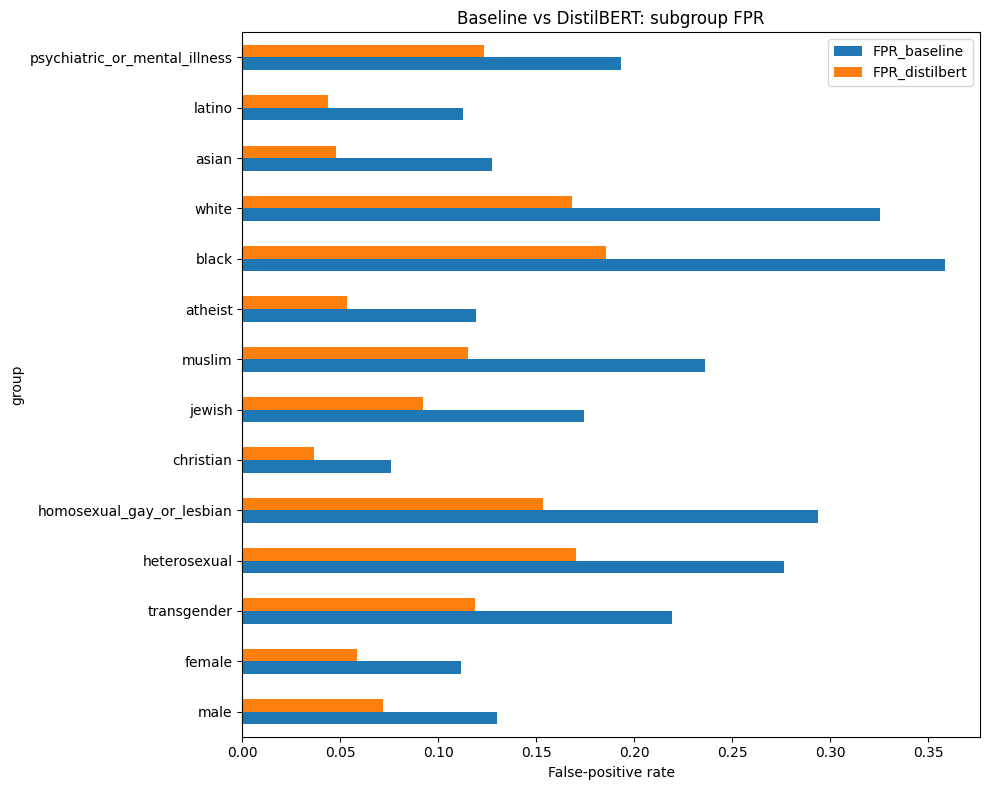

In [27]:
# SECTION F: BASELINE VS DISTILBERT

BASELINE_PATH = find_file("test_predictions.parquet")

# Set this to the threshold actually used by the baseline.
# Replace 0.5 if Member 1 tuned a different threshold.
BASELINE_THRESHOLDS = {label: 0.5 for label in LABELS}

if BASELINE_PATH is None:
    print(
        "Baseline file not found. Ask Member 1 for baseline test "
        "probabilities with matching comment IDs. "
        "This comparison cannot be completed yet."
    )

elif "id" not in test.columns:
    print(
        "The transformer test file has no id column. "
        "Request matching IDs before comparing models."
    )

else:
    baseline = pd.read_parquet(BASELINE_PATH)

    if "id" not in baseline.columns:
        raise ValueError("Baseline predictions must contain an id column.")

    baseline_prob_col = "prob_toxic"
    if baseline_prob_col not in baseline.columns:
        raise ValueError("Baseline file must contain prob_toxic.")

    if baseline["id"].duplicated().any():
        raise ValueError("Baseline file has duplicate IDs.")

    # Keep identity annotations and true labels from the main test file.
    comparison = test.merge(
        baseline[["id", baseline_prob_col]].rename(
            columns={"prob_toxic": "baseline_prob"}
        ),
        on="id",
        how="inner",
        validate="one_to_one"
    )

    comparison = comparison[
        comparison["has_identity_labels"].eq(True)
    ].copy()

    print("Matched annotated test comments:", len(comparison))

    if comparison.empty:
        raise ValueError("No matching annotated comments found.")

    comparison["prob_toxic"] = comparison["baseline_prob"]

    comparison_rows = []

    # Same comments, same identity groups, two models
    for group in IDENTITY_COLS:
        group_mask = comparison[group].ge(0.5).fillna(False)
        group_df = comparison.loc[group_mask]

        if len(group_df) < 100:
            continue

        bert_df = group_df.copy()
        bert_df["prob_toxic"] = group_df["prob_toxic"]

        base_df = group_df.copy()
        base_df["prob_toxic"] = group_df["baseline_prob"]

        bert_rates = calculate_rates(bert_df, "toxic", THR["toxic"])
        base_rates = calculate_rates(
            base_df, "toxic", BASELINE_THRESHOLDS["toxic"]
        )

        comparison_rows.append({
            "group": group,
            "n": len(group_df),
            "FPR_baseline": base_rates["FPR"],
            "FPR_distilbert": bert_rates["FPR"],
            "FNR_baseline": base_rates["FNR"],
            "FNR_distilbert": bert_rates["FNR"],
            "FPR_change": bert_rates["FPR"] - base_rates["FPR"],
            "FNR_change": bert_rates["FNR"] - base_rates["FNR"]
        })

    comparison_table = pd.DataFrame(comparison_rows)

    comparison_table.to_csv(
        OUT / "baseline_vs_distilbert_fairness.csv",
        index=False
    )

    print(comparison_table.round(4).to_string(index=False))

    if not comparison_table.empty:
        comparison_table.set_index("group")[
            ["FPR_baseline", "FPR_distilbert"]
        ].plot.barh(figsize=(10, 8))

        plt.xlabel("False-positive rate")
        plt.title("Baseline vs DistilBERT: subgroup FPR")
        plt.tight_layout()
        plt.savefig(OUT / "baseline_vs_distilbert_fpr.png", dpi=150)
        plt.show()

Exploratory group-aware threshold mitigation

In [29]:
# SECTION G: MITIGATION
# Requires validation predictions with true labels, probabilities,
# and the identity columns.

VAL_PATH = find_file("val_predictions.parquet")
LABEL = "toxic"

if VAL_PATH is None:
    print(
        "Skipping mitigation: val_predictions.parquet not found. "
        "Do not tune mitigation thresholds on the test set."
    )

else:
    try:
        # Check if the file is empty first
        if VAL_PATH.stat().st_size == 0:
            raise ValueError("The file is 0 bytes (empty).")

        val = pd.read_parquet(VAL_PATH)

        required_val = (
            [f"true_{LABEL}", f"prob_{LABEL}"]
            + IDENTITY_COLS
        )
        missing_val = [c for c in required_val if c not in val.columns]

        if missing_val:
            raise ValueError(
                f"Validation file is missing required columns: {missing_val}"
            )

        if "has_identity_labels" in val.columns:
            val = val[val["has_identity_labels"].eq(True)].copy()
        else:
            val = val[val[IDENTITY_COLS].notna().any(axis=1)].copy()

        # Target overall validation FPR at the global threshold
        target_fpr = calculate_rates(val, LABEL)["FPR"]

        def choose_group_threshold(group_df, target):
            negatives = group_df.loc[
                group_df[f"true_{LABEL}"] == 0,
                f"prob_{LABEL}"
            ].dropna().to_numpy()

            if len(negatives) == 0:
                return np.nan

            # Approximate the threshold for the target FPR
            return float(np.quantile(negatives, 1 - target))

        group_thresholds = {}

        for group in IDENTITY_COLS:
            group_df = val[val[group].ge(0.5).fillna(False)]

            if len(group_df) < 100:
                continue

            group_thresholds[group] = choose_group_threshold(
                group_df, target_fpr
            )

        group_thresholds = {
            g: t for g, t in group_thresholds.items()
            if np.isfinite(t)
        }

        with open(OUT / "group_thresholds.json", "w") as f:
            json.dump(group_thresholds, f, indent=2)

        # Evaluate the learned thresholds on the test set.
        test_fair = sub.copy()
        test_overall = calculate_rates(test_fair, LABEL)["FPR"]

        mitigation_rows = []

        for group, threshold in group_thresholds.items():
            group_df = test_fair[
                test_fair[group].ge(0.5).fillna(False)
            ]

            before = calculate_rates(group_df, LABEL)
            after = calculate_rates(group_df, LABEL, threshold)

            mitigation_rows.append({
                "group": group,
                "n": len(group_df),
                "threshold_global": THR[LABEL],
                "threshold_group": threshold,
                "FPR_before": before["FPR"],
                "FPR_after": after["FPR"],
                "FNR_before": before["FNR"],
                "FNR_after": after["FNR"],
                "FPR_gap_before": abs(before["FPR"] - test_overall),
                "FPR_gap_after": abs(after["FPR"] - test_overall)
            })

        mitigation = pd.DataFrame(mitigation_rows)
        mitigation.to_csv(
            OUT / "mitigation_group_thresholds.csv",
            index=False
        )

        print(mitigation.round(4).to_string(index=False))

        if not mitigation.empty:
            print(
                "\nMean absolute FPR gap before:",
                round(mitigation["FPR_gap_before"].mean(), 4)
            )
            print(
                "Mean absolute FPR gap after:",
                round(mitigation["FPR_gap_after"].mean(), 4)
            )
            print(
                "Mean FNR before:",
                round(mitigation["FNR_before"].mean(), 4)
            )
            print(
                "Mean FNR after:",
                round(mitigation["FNR_after"].mean(), 4)
            )
    except Exception as e:
        print(f"Error reading or parsing validation file: {e}")
        print("Please check if 'val_predictions.parquet' is corrupted or empty (0 bytes).")

                        group    n  threshold_global  threshold_group  FPR_before  FPR_after  FNR_before  FNR_after  FPR_gap_before  FPR_gap_after
                         male 4161            0.7202           0.8054      0.0718     0.0486      0.2958     0.3682          0.0263         0.0032
                       female 4767            0.7202           0.7668      0.0585     0.0452      0.3446     0.3800          0.0131         0.0002
                  transgender  273            0.7202           0.8266      0.1187     0.0639      0.4259     0.5741          0.0733         0.0185
                 heterosexual  117            0.7202           0.8780      0.1702     0.0532      0.4348     0.6522          0.1248         0.0078
    homosexual_gay_or_lesbian  891            0.7202           0.8703      0.1534     0.0527      0.3283     0.5811          0.1079         0.0073
                    christian 4480            0.7202           0.7051      0.0365     0.0394      0.3829     0.3728   

In [31]:
import shutil
from pathlib import Path
from google.colab import files

folder = Path("/content/member3_outputs")

if not folder.exists() or not any(folder.iterdir()):
    raise FileNotFoundError("member3_outputs folder is missing or empty.")

zip_path = shutil.make_archive(
    "/content/member3_outputs",
    "zip",
    root_dir="/content",
    base_dir="member3_outputs"
)

print("ZIP created successfully!")
print("Files included:", sum(1 for p in folder.rglob("*") if p.is_file()))

files.download(zip_path)

ZIP created successfully!
Files included: 10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>